# **OPT-CNN-ABL**

Estudio de ablación: se entrena la arquitectura **CNN-B desde cero** (pesos aleatorios) sobre el dataset ICBA, sin preentrenamiento en dataset sintético. El objetivo es aislar el efecto del preentrenamiento de Fase 1 comparando con CNN-FT.

In [1]:
import os
import gc
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from pathlib import Path
from PIL import Image
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from optuna.trial import TrialState
from tqdm.auto import tqdm as _tqdm
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_virtual_device_configuration(
        gpus[0],
        [tf.config.experimental.VirtualDeviceConfiguration(memory_limit=8192)]
    )
    print(f'GPU encontrada: {gpus[0].name} (límite: 8 GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite: 8 GB)


-------------
## **Búsqueda de Hiperparámetros**
---------------

In [3]:
# ── Rutas ─────────────────────────────────────────────────────────────────────
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset ICBA Folds'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 3' / 'Modelo CNN'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [10]:
# ── Experimento ───────────────────────────────────────────────────────────────
EXPERIMENT_NAME = 'OPT-CNN-ABL'
ARQUITECTURA    = 'CNN-B'
DATASET         = 'ICBA'

# ── Imagen ────────────────────────────────────────────────────────────────────
IMG_HEIGHT  = 192
IMG_WIDTH   = 352
CHANNELS    = 1
NUM_CLASSES = 4
CLASSES     = ['Am', 'HTA', 'EAo', 'MCH']

# ── Dataset folds ─────────────────────────────────────────────────────────────
TRAIN_FOLDS = [1, 2, 3, 4]
VAL_FOLD    = 5

# ── Entrenamiento ─────────────────────────────────────────────────────────────
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
BATCH_SIZE    = 16
N_TRIALS      = 30
EPOCH_MAX     = 100
SEED          = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# ── Callbacks ─────────────────────────────────────────────────────────────────
ES_PATIENCE         = 8
ES_MIN_DELTA        = 0.0001
METRIC              = 'val_loss'
DIRECTION           = 'minimize'
N_STARTUP_TRIALS    = 8
N_WARMUP_STEPS      = 10
INTERVAL_STEPS      = 1
N_MIN_TRIALS_PRUNER = 3
RLR_FACTOR          = 0.5
RLR_PATIENCE        = 5
RLR_MIN_DELTA       = 0.0001
RLR_MIN_LR          = 1e-7

# ── Espacio de búsqueda ───────────────────────────────────────────────────────
NUM_BLOCKS_RANGE  = (1, 3)      # menos bloques porque el dataset es más chico
BASE_FILTERS_OPTS = [32, 64]
DROPOUT_RANGE     = (0.1, 0.4)
LR_RANGE          = (1e-4, 1e-3)
DENSE_UNITS       = 128         
OPTIMIZER         = 'Adam'      

### **Arquitectura**

Estudio de ablación: CNN-B entrenada **desde cero** sobre ICBA (sin preentrenamiento en dataset sintético). 

El espacio de búsqueda incluye los mismos hiperparámetros que el Optuna de Fase 1 (`num_blocks`, `base_filters`, `dropout`, `learning_rate`), con `num_blocks` ∈ {1, 2, 3} (reducido respecto a Fase 1 donde era {4, 5}) para adaptar la capacidad del modelo al tamaño del dataset ICBA. `dense_units` y el optimizador se fijan en 128 y Adam respectivamente.

In [11]:
def build_cnn_b(num_blocks, base_filters, dense_units, dropout,
                input_shape=(192, 352, 1), num_classes=4):
    inputs = tf.keras.Input(shape=input_shape)
    x = inputs

    for i in range(num_blocks):
        filters = base_filters * (2 ** i)
        drop_i  = min(dropout + i * 0.05, 0.4)

        residual = x

        x = layers.Conv2D(filters, (3, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

        x = layers.Conv2D(filters, (3, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)

        if residual.shape[-1] != filters:
            residual = layers.Conv2D(filters, (1, 1), padding='same')(residual)
            residual = layers.BatchNormalization()(residual)

        x = layers.Add()([x, residual])
        x = layers.ReLU()(x)

        x = layers.MaxPooling2D((2, 2))(x)
        x = layers.Dropout(drop_i)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs=inputs, outputs=x, name='CNN_B_Ablation')

### **Carga de Datos**

Dataset ICBA con folds 1–4 para entrenamiento y fold 5 para validación. Los datos se cargan en memoria antes del estudio Optuna.

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

def load_fold_images(fold_dirs, classes):
    X, y = [], []
    for fold_dir in fold_dirs:
        for label_idx, cls in enumerate(classes):
            cls_dir = fold_dir / cls
            if not cls_dir.exists():
                print(f'  Advertencia: {cls_dir} no existe')
                continue
            for f in sorted(cls_dir.iterdir()):
                if f.suffix.lower() in ('.jpg', '.jpeg'):
                    img = np.array(Image.open(f).convert('L'))
                    img = img[:, :, np.newaxis]   # H×W×1 grayscale
                    X.append(img)
                    y.append(label_idx)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32)

print('Cargando datos en memoria...')
train_dirs = [DATA_PATH / 'train' / f'fold {i}' for i in TRAIN_FOLDS]
val_dirs   = [DATA_PATH / 'train' / f'fold {VAL_FOLD}']

X_train, y_train = load_fold_images(train_dirs, CLASSES)
X_val,   y_val   = load_fold_images(val_dirs,   CLASSES)

# Shuffle con seed fija una sola vez antes de Optuna
np.random.seed(SEED)
idx     = np.random.permutation(len(X_train))
X_train = X_train[idx]
y_train = y_train[idx]

print(f'\nDatos cargados:')
print(f'  X_train : {X_train.shape}   y_train : {y_train.shape}')
print(f'  X_val   : {X_val.shape}     y_val   : {y_val.shape}')
print(f'\nDistribución de clases:')
header = f"{'Clase':<8}" + f"{'train':>8}" + f"{'val':>8}"
print(header)
print('-' * len(header))
for i, cls in enumerate(CLASSES):
    print(f'{cls:<8}{(y_train == i).sum():>8}{(y_val == i).sum():>8}')
print(f"{'TOTAL':<8}{len(y_train):>8}{len(y_val):>8}")

Cargando datos en memoria...

Datos cargados:
  X_train : (442, 192, 352, 1)   y_train : (442,)
  X_val   : (107, 192, 352, 1)     y_val   : (107,)

Distribución de clases:
Clase      train     val
------------------------
Am           120      29
HTA          114      28
EAo          124      30
MCH           84      20
TOTAL        442     107


### **Estudio de Optuna**

In [13]:
class _DuplicateParamsError(Exception):
    pass


class OptunaPruningCallback(tf.keras.callbacks.Callback):
    def __init__(self, trial, monitor='val_loss'):
        super().__init__()
        self.trial   = trial
        self.monitor = monitor

    def on_epoch_end(self, epoch, logs=None):
        value = logs.get(self.monitor)
        if value is not None:
            self.trial.report(value, epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    # ── Sugerir hiperparámetros ───────────────────────────────────────────────
    num_blocks   = trial.suggest_int('num_blocks',               *NUM_BLOCKS_RANGE)
    base_filters = trial.suggest_categorical('base_filters',     BASE_FILTERS_OPTS)
    dropout      = trial.suggest_float('dropout',                *DROPOUT_RANGE)
    lr           = trial.suggest_float('learning_rate',          *LR_RANGE, log=True)

    # ── Anti-duplicado ────────────────────────────────────────────────────────
    for past in trial.study.trials:
        if past.number == trial.number:
            continue
        if past.state != TrialState.COMPLETE:
            continue
        if past.params == trial.params:
            print(f'  [dup] Trial {trial.number} repite trial {past.number} — descartado')
            raise _DuplicateParamsError(f'Duplicado del trial {past.number}')

    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    train_ds = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
        .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val))
        .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    model = build_cnn_b(
        num_blocks   = num_blocks,
        base_filters = base_filters,
        dense_units  = DENSE_UNITS,
        dropout      = dropout,
        input_shape  = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
        num_classes  = NUM_CLASSES,
    )
    model.compile(
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )

    history = model.fit(
        train_ds,
        validation_data = val_ds,
        epochs          = EPOCH_MAX,
        callbacks       = [
            EarlyStopping(
                monitor              = METRIC,
                patience             = ES_PATIENCE,
                min_delta            = ES_MIN_DELTA,
                restore_best_weights = True,
            ),
            ReduceLROnPlateau(
                monitor   = METRIC,
                factor    = RLR_FACTOR,
                patience  = RLR_PATIENCE,
                min_delta = RLR_MIN_DELTA,
                min_lr    = RLR_MIN_LR,
            ),
            OptunaPruningCallback(trial, monitor=METRIC),
        ],
        verbose = 0,
    )

    trial.set_user_attr('epochs_trained', len(history.history[METRIC]))
    result = min(history.history[METRIC])

    del model, train_ds, val_ds, history
    gc.collect()
    tf.keras.backend.clear_session()
    gc.collect()

    return result

In [14]:
_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')

study = optuna.create_study(
    direction      = DIRECTION,
    study_name     = EXPERIMENT_NAME,
    storage        = f'sqlite:///{_db_path}',
    load_if_exists = True,
    sampler        = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_STARTUP_TRIALS),
    pruner         = optuna.pruners.MedianPruner(
        n_startup_trials = N_STARTUP_TRIALS,
        n_warmup_steps   = N_WARMUP_STEPS,
        n_min_trials     = N_MIN_TRIALS_PRUNER,
        interval_steps   = INTERVAL_STEPS,
    ),
)

# ── Marcar zombies como FAIL ──────────────────────────────────────────────────
_all_trials = study.trials
_zombies = [t for t in _all_trials if t.state == TrialState.RUNNING]
if _zombies:
    for t in _zombies:
        try:
            study._storage.set_trial_state_values(t._trial_id, TrialState.FAIL, {})
        except Exception:
            pass
    _all_trials = study.trials

# ── Reintentar último trial fallido (solo si no es un duplicado) ──────────────
_failed = [t for t in _all_trials if t.state == TrialState.FAIL and t.params]
if _failed:
    last_failed       = max(_failed, key=lambda t: t.number)
    last_done         = max((t.number for t in _all_trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)), default=-1)
    _completed_params = [t.params for t in _all_trials if t.state == TrialState.COMPLETE]
    if last_failed.number > last_done and last_failed.params not in _completed_params:
        print(f'  Trial {last_failed.number} fallido → reintento')
        study.enqueue_trial(last_failed.params)

# ── Trials restantes ──────────────────────────────────────────────────────────
n_completados = len([t for t in study.trials
                     if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
n_restantes   = max(0, N_TRIALS - n_completados)
print(f'Trials completados: {n_completados} — Trials restantes: {n_restantes}')

# ── Progress bar ──────────────────────────────────────────────────────────────
_pbar = _tqdm(total=N_TRIALS, initial=n_completados, desc='Optuna', unit='trial')

def _trial_callback(study, trial):
    n_done = len([t for t in study.trials
                  if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
    if trial.state == TrialState.COMPLETE:
        _pbar.update(1)
        best = study.best_trial
        _pbar.set_postfix({
            'mejor_trial': best.number,
            'mejor_loss':  f'{best.value:.4f}',
            'ultimo':      f'{trial.value:.4f}',
        })
        print(f'Trial {trial.number:>3} | val_loss={trial.value:.4f} | mejor={best.value:.4f} (t{best.number}) | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.PRUNED:
        _pbar.update(1)
        _pbar.set_postfix({'ultimo': 'podado'})
        print(f'Trial {trial.number:>3} | PODADO | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.FAIL:
        _pbar.set_postfix({'ultimo': 'FAILED'})
        print(f'Trial {trial.number:>3} | FAILED | {n_done}/{N_TRIALS}')

study.optimize(
    objective,
    n_trials          = n_restantes,
    show_progress_bar = False,
    gc_after_trial    = True,
    catch             = (tf.errors.ResourceExhaustedError, _DuplicateParamsError),
    callbacks         = [_trial_callback],
)
_pbar.close()

Trials completados: 20 — Trials restantes: 10


Optuna:  67%|######6   | 20/30 [00:00<?, ?trial/s]

Trial  20 | val_loss=1.3996 | mejor=0.8235 (t8) | 21/30
Trial  21 | val_loss=1.3981 | mejor=0.8235 (t8) | 22/30
Trial  22 | PODADO | 23/30
Trial  23 | PODADO | 24/30
Trial  24 | PODADO | 25/30
Trial  25 | val_loss=1.4018 | mejor=0.8235 (t8) | 26/30
Trial  26 | val_loss=1.3876 | mejor=0.8235 (t8) | 27/30
Trial  27 | val_loss=1.4515 | mejor=0.8235 (t8) | 28/30
Trial  28 | PODADO | 29/30
Trial  29 | PODADO | 30/30


In [15]:
# ── Cargar estudio y guardar CSV ──────────────────────────────────────────────
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)
df_study = study.trials_dataframe()
display(df_study)

df_clean = df_study[df_study['state'].isin(['COMPLETE', 'PRUNED'])].copy()
df_clean = df_clean.reset_index(drop=True)
df_clean.index = df_clean.index + 1
df_clean.index.name = 'trial'

param_cols = sorted([c for c in df_clean.columns if c.startswith('params_')])
cols_order = ['value', 'state', 'datetime_start', 'datetime_complete',
              'duration', 'user_attrs_epochs_trained'] + param_cols
df_clean = df_clean[[c for c in cols_order if c in df_clean.columns]]
df_clean = df_clean.rename(columns={
    'datetime_start':            't_start',
    'datetime_complete':         't_finish',
    'user_attrs_epochs_trained': 'epochs_trained',
    **{c: c.replace('params_', '') for c in param_cols}
})
for col in ['t_start', 't_finish']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].dt.strftime('%d/%m - %H:%M')
if 'duration' in df_clean.columns:
    df_clean['duration'] = df_clean['duration'].apply(
        lambda x: f"{int(x.total_seconds()//3600):02d}:{int((x.total_seconds()%3600)//60):02d}:{int(x.total_seconds()%60):02d}" if pd.notna(x) else ''
    )
df_clean.to_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv')
print(f'CSV guardado: {len(df_clean)} trials')

,number,value,datetime_start,datetime_complete,duration,params_base_filters,params_dropout,params_learning_rate,params_num_blocks,user_attrs_epochs_trained,state
0,0,1.399645,2026-08-19 12:23:20.933437,2026-08-19 12:24:18.762641,0 days 00:00:57.829204,32,0.279598,0.000143,2,9.0,COMPLETE
1,1,1.387995,2026-08-19 12:24:18.970073,2026-08-19 12:24:58.785740,0 days 00:00:39.815667,64,0.280335,0.000511,1,9.0,COMPLETE
2,2,1.383213,2026-08-19 12:24:59.125133,2026-08-19 12:25:21.425574,0 days 00:00:22.300441,32,0.163702,0.000152,1,9.0,COMPLETE
3,3,1.385506,2026-08-19 12:25:21.728149,2026-08-19 12:26:01.382377,0 days 00:00:39.654228,64,0.229584,0.000196,1,9.0,COMPLETE
4,4,1.408493,2026-08-19 12:26:01.686105,2026-08-19 12:26:58.260579,0 days 00:00:56.574474,64,0.209909,0.000286,2,9.0,COMPLETE
5,5,1.388425,2026-08-19 12:26:58.639975,2026-08-19 12:28:05.386208,0 days 00:01:06.746233,64,0.277724,0.000111,3,9.0,COMPLETE
6,6,1.056780,2026-08-19 12:28:05.778591,2026-08-19 12:29:39.938019,0 days 00:01:34.159428,32,0.384666,0.000924,2,29.0,COMPLETE
7,7,1.392604,2026-08-19 12:29:40.373557,2026-08-19 12:30:17.672593,0 days 00:00:37.299036,32,0.305270,0.000276,3,9.0,COMPLETE
8,8,0.823520,2026-08-19 12:30:18.129667,2026-08-19 12:32:29.805415,0 days 00:02:11.675748,32,0.390861,0.000902,2,42.0,COMPLETE
9,9,1.439064,2026-08-19 12:32:30.361145,2026-08-19 12:33:07.529035,0 days 00:00:37.167890,32,0.391923,0.000948,3,9.0,COMPLETE


CSV guardado: 30 trials


In [ ]:
import IPython
print('Reiniciando kernel...')
IPython.Application.instance().kernel.do_shutdown(restart=True)

-------------
## **Resultados**
---------------

In [16]:
# ── Reconstruir contexto post-restart ─────────────────────────────────────────
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from optuna.trial import TrialState
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

REPO_ROOT       = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
MODELS_PATH     = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 3' / 'Modelo CNN'
EXPERIMENT_NAME = 'OPT-CNN-ABL'
DIRECTION       = 'minimize'

_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)

n_complete = len([t for t in study.trials if t.state == TrialState.COMPLETE])
n_pruned   = len([t for t in study.trials if t.state == TrialState.PRUNED])
print(f'Trials completos: {n_complete} | Podados: {n_pruned} | Mejor val_loss: {study.best_value:.4f} (trial {study.best_trial.number})')
print(f'Mejores parámetros: {study.best_trial.params}')

Trials completos: 25 | Podados: 5 | Mejor val_loss: 0.8235 (trial 8)
Mejores parámetros: {'num_blocks': 2, 'base_filters': 32, 'dropout': 0.3908611332363599, 'learning_rate': 0.0009017971867796207}


### **Evolución del Estudio**

In [17]:
df_trials = pd.read_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv', index_col='trial')

param_cols = [c for c in df_trials.columns if c not in
              ['value', 'state', 't_start', 't_finish', 'duration', 'epochs_trained']]

fmt = {'value': '{:.4f}'}
if 'dropout' in df_trials.columns:
    fmt['dropout'] = '{:.4f}'
if 'learning_rate' in df_trials.columns:
    fmt['learning_rate'] = '{:.2e}'

display(df_trials.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,base_filters,dropout,learning_rate,num_blocks
trial,,,,,,,,,,
1,1.3996,COMPLETE,19/08 - 12:23,19/08 - 12:24,00:00:57,9.000000,32,0.2796,1.43e-04,2
2,1.3880,COMPLETE,19/08 - 12:24,19/08 - 12:24,00:00:39,9.000000,64,0.2803,5.11e-04,1
3,1.3832,COMPLETE,19/08 - 12:24,19/08 - 12:25,00:00:22,9.000000,32,0.1637,1.52e-04,1
4,1.3855,COMPLETE,19/08 - 12:25,19/08 - 12:26,00:00:39,9.000000,64,0.2296,1.96e-04,1
5,1.4085,COMPLETE,19/08 - 12:26,19/08 - 12:26,00:00:56,9.000000,64,0.2099,2.86e-04,2
6,1.3884,COMPLETE,19/08 - 12:26,19/08 - 12:28,00:01:06,9.000000,64,0.2777,1.11e-04,3
7,1.0568,COMPLETE,19/08 - 12:28,19/08 - 12:29,00:01:34,29.000000,32,0.3847,9.24e-04,2
8,1.3926,COMPLETE,19/08 - 12:29,19/08 - 12:30,00:00:37,9.000000,32,0.3053,2.76e-04,3
9,0.8235,COMPLETE,19/08 - 12:30,19/08 - 12:32,00:02:11,42.000000,32,0.3909,9.02e-04,2


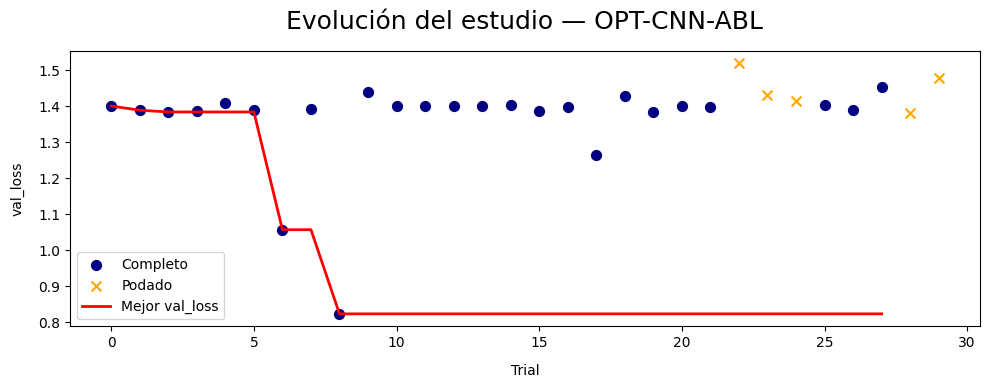

In [18]:
complete = [t for t in study.trials if t.state == TrialState.COMPLETE]
pruned   = [t for t in study.trials if t.state == TrialState.PRUNED]

fig, ax = plt.subplots(figsize=(10, 4))

if complete:
    ax.scatter([t.number for t in complete], [t.value for t in complete],
               color='navy', s=50, label='Completo')

if pruned:
    pruned_y = [list(t.intermediate_values.values())[-1] if t.intermediate_values else None
                for t in pruned]
    ax.scatter([t.number for t in pruned], pruned_y,
               color='orange', s=50, marker='x', label='Podado')

if complete:
    sorted_complete = sorted(complete, key=lambda t: t.number)
    best_so_far = pd.Series([t.value for t in sorted_complete]).cummin()
    ax.plot([t.number for t in sorted_complete], best_so_far,
            color='red', linewidth=2, label='Mejor val_loss')

ax.set_xlabel('Trial', labelpad=10)
ax.set_ylabel('val_loss', labelpad=10)
ax.set_title(f'Evolución del estudio — {EXPERIMENT_NAME}', fontsize=18, y=1.05)
ax.legend()
plt.tight_layout()
plt.show()

### **Análisis por Hiperparámetro**

In [19]:
try:
    import plotly
    fig = optuna.visualization.plot_param_importances(study)
    fig.update_traces(marker_color='navy')
    fig.update_layout(title=f'Importancia de hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado — instalar con: pip install plotly')

/tmp/ipykernel_1362435/3577916280.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(
/tmp/ipykernel_1362435/3577916280.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(


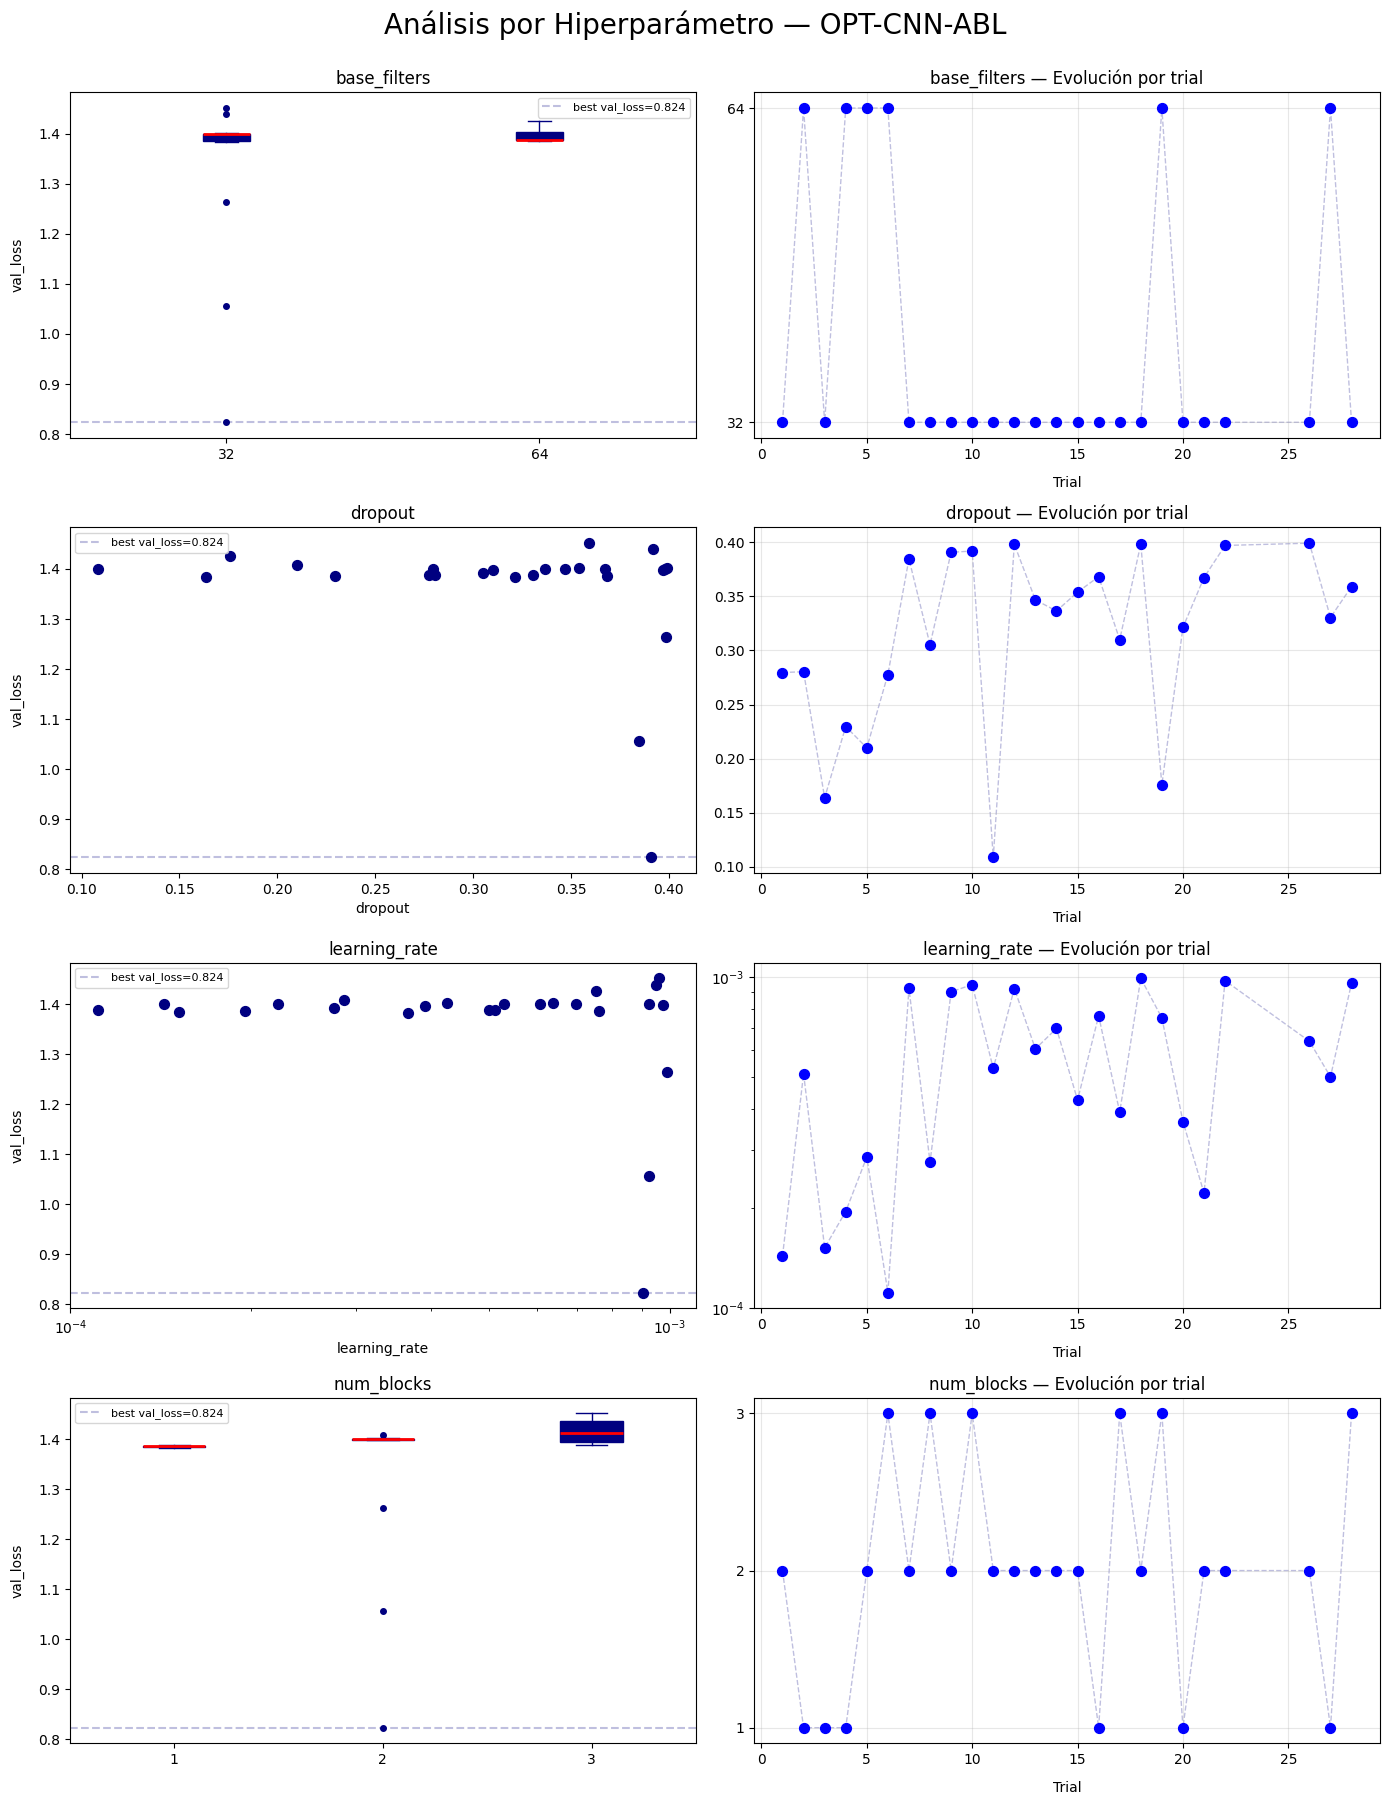

In [20]:
df_complete = df_trials[df_trials['state'] == 'COMPLETE'].copy()
df_complete['number'] = df_complete.index

n_params = len(param_cols)
fig, axes = plt.subplots(n_params, 2, figsize=(14, 4.5 * n_params))
if n_params == 1:
    axes = axes.reshape(1, 2)

for i, param in enumerate(param_cols):
    ax_left  = axes[i, 0]
    ax_right = axes[i, 1]

    is_cat = df_complete[param].dtype == object or df_complete[param].nunique() <= 6

    if is_cat:
        groups = sorted(df_complete[param].dropna().unique())
        data   = [df_complete[df_complete[param] == g]['value'].values for g in groups]
        ax_left.boxplot(
            data, labels=[str(g) for g in groups], patch_artist=True,
            boxprops    = dict(facecolor='navy', color='navy'),
            medianprops = dict(color='red', linewidth=2),
            whiskerprops= dict(color='navy'),
            capprops    = dict(color='navy'),
            flierprops  = dict(markerfacecolor='navy', markeredgecolor='navy', marker='o', markersize=4),
        )
    else:
        ax_left.scatter(df_complete[param], df_complete['value'], color='navy', s=50)
        if param == 'learning_rate':
            ax_left.set_xscale('log')
        ax_left.set_xlabel(param)

    ax_left.axhline(study.best_value, color='navy', linestyle='--', alpha=0.25, linewidth=1.5,
                    label=f'best val_loss={study.best_value:.3f}')
    ax_left.set_ylabel('val_loss', labelpad=10)
    ax_left.set_title(param)
    ax_left.legend(fontsize=8)

    df_sorted = df_complete.sort_values('number')
    if is_cat:
        cats    = sorted(df_complete[param].dropna().unique())
        cat_map = {c: j for j, c in enumerate(cats)}
        y_vals  = df_sorted[param].map(cat_map)
        ax_right.plot(df_sorted['number'], y_vals, color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], y_vals, color='blue', s=50, zorder=2)
        ax_right.set_yticks(range(len(cats)))
        ax_right.set_yticklabels([str(c) for c in cats])
    else:
        ax_right.plot(df_sorted['number'], df_sorted[param], color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], df_sorted[param], color='blue', s=50, zorder=2)
        if param == 'learning_rate':
            ax_right.set_yscale('log')

    ax_right.set_xlabel('Trial', labelpad=10)
    ax_right.set_title(f'{param} — Evolución por trial')
    ax_right.grid(True, alpha=0.3)

plt.suptitle(f'Análisis por Hiperparámetro — {EXPERIMENT_NAME}', fontsize=20, y=1)
plt.tight_layout()
plt.show()

### **Combinación de Hiperparámetros**

In [21]:
try:
    import plotly
    fig = optuna.visualization.plot_parallel_coordinate(study)
    fig.update_layout(title=f'Combinación de Hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado')

In [22]:
df_ranked = df_trials[df_trials['state'].isin(['COMPLETE', 'PRUNED'])].sort_values('value')
display(df_ranked.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,base_filters,dropout,learning_rate,num_blocks
trial,,,,,,,,,,
9,0.8235,COMPLETE,19/08 - 12:30,19/08 - 12:32,00:02:11,42.000000,32,0.3909,9.02e-04,2
7,1.0568,COMPLETE,19/08 - 12:28,19/08 - 12:29,00:01:34,29.000000,32,0.3847,9.24e-04,2
18,1.2633,COMPLETE,19/08 - 12:36,19/08 - 12:38,00:01:19,24.000000,32,0.3984,9.91e-04,2
29,1.3817,PRUNED,19/08 - 12:46,19/08 - 12:47,00:00:39,-,32,0.2953,8.17e-04,2
20,1.3831,COMPLETE,19/08 - 12:39,19/08 - 12:39,00:00:24,9.000000,32,0.3214,3.66e-04,1
3,1.3832,COMPLETE,19/08 - 12:24,19/08 - 12:25,00:00:22,9.000000,32,0.1637,1.52e-04,1
4,1.3855,COMPLETE,19/08 - 12:25,19/08 - 12:26,00:00:39,9.000000,64,0.2296,1.96e-04,1
16,1.3864,COMPLETE,19/08 - 12:35,19/08 - 12:36,00:00:24,9.000000,32,0.3682,7.63e-04,1
27,1.3876,COMPLETE,19/08 - 12:45,19/08 - 12:46,00:00:42,9.000000,64,0.3305,4.99e-04,1
